# TA-02: Prediksi Berat Ikan Berdasarkan Panjang Ikan
**Nama:** [ISI NAMA]  
**NIM:** [ISI NIM]

Dataset: Fish Market (Kaggle). Jika di Colab, upload `Fish.csv` lewat panel Files.

## 1. Muat Data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

df = pd.read_csv("Fish.csv", encoding="utf-8-sig")
print(df.shape)
df.head()

(159, 7)


,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [2]:
df.info()
print(df.isna().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    str    
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 8.8 KB
Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64


,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


## 2. Pembersihan Data
Ada satu ikan dengan berat 0 gram (tidak masuk akal), maka dihapus.

In [3]:
print(df[df["Weight"] <= 0])
df = df[df["Weight"] > 0].reset_index(drop=True)
print(df.shape)

   Species  Weight  Length1  Length2  Length3  Height   Width
40   Roach     0.0     19.0     20.5     22.8  6.4752  3.3516
(158, 7)


## 3. EDA dan Validasi Asumsi Linear

Weight     1.000
Length1    0.916
Length2    0.919
Length3    0.923
Height     0.724
Width      0.887
Name: Weight, dtype: float64


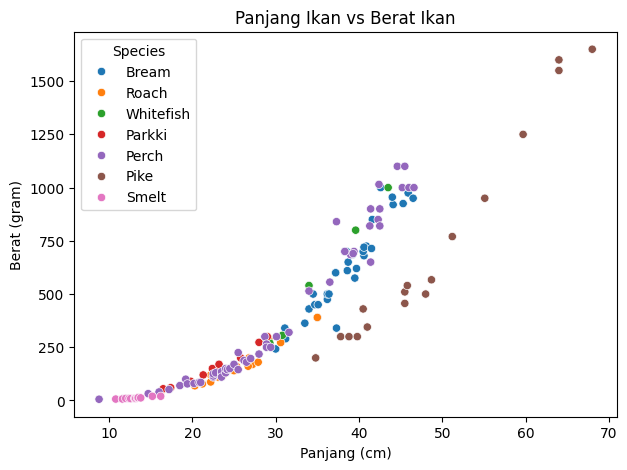

In [4]:
print(df[["Weight","Length1","Length2","Length3","Height","Width"]].corr()["Weight"].round(3))

plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x="Length3", y="Weight", hue="Species")
plt.title("Panjang Ikan vs Berat Ikan"); plt.xlabel("Panjang (cm)"); plt.ylabel("Berat (gram)")
plt.show()

Scatterplot menunjukkan tren naik yang kuat (korelasi sekitar 0,92), sehingga regresi linear layak dicoba. Pola sedikit melengkung karena berat tumbuh lebih cepat daripada panjang.

## 4. Pelatihan Model

In [5]:
X = df[["Length3"]]; y = df["Weight"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

## 5. Evaluasi

R2   : 0.8622
RMSE : 136.01 gram
MAE  : 102.42 gram
Intercept: -490.6723
Koefisien: 28.3944


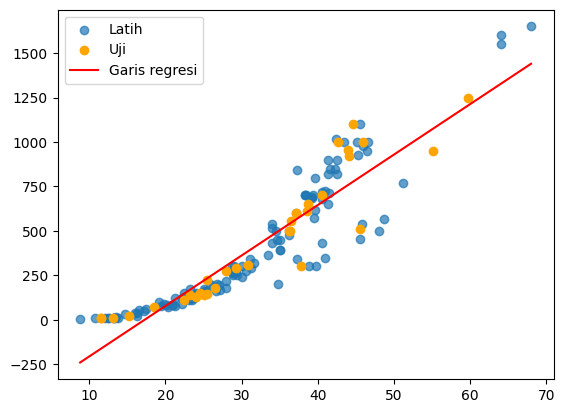

In [6]:
r2 = r2_score(y_test, pred); rmse = np.sqrt(mean_squared_error(y_test, pred)); mae = mean_absolute_error(y_test, pred)
print(f"R2   : {r2:.4f}\nRMSE : {rmse:.2f} gram\nMAE  : {mae:.2f} gram")
print(f"Intercept: {model.intercept_:.4f}\nKoefisien: {model.coef_[0]:.4f}")

plt.scatter(X_train, y_train, label="Latih", alpha=.7); plt.scatter(X_test, y_test, label="Uji", color="orange")
xs = pd.DataFrame(np.linspace(X.Length3.min(), X.Length3.max(), 100), columns=["Length3"])
plt.plot(xs, model.predict(xs), color="red", label="Garis regresi"); plt.legend(); plt.show()

## 6. Interpretasi
- **Koefisien (sekitar 28,39):** setiap tambahan 1 cm panjang ikan diperkirakan menambah berat rata-rata sekitar 28 gram.
- **Intercept (sekitar -490,67):** nilai matematis saat panjang 0 cm. Secara fisik tidak bermakna (berat negatif), dan model memprediksi berat di bawah nol untuk panjang kurang dari sekitar 17 cm, jadi model kurang andal untuk ikan kecil.
- **R2 (sekitar 0,86):** sekitar 86% variasi berat dijelaskan oleh panjang ikan.
- **RMSE (sekitar 136 gram):** rata-rata prediksi meleset sekitar 136 gram.

## 7. Simpan Model (Joblib)

In [7]:
joblib.dump(model, "fish_model.joblib")
loaded = joblib.load("fish_model.joblib")
loaded.predict(pd.DataFrame([[30]], columns=["Length3"]))

array([361.15841472])